In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the Online Retail dataset
data_path = Path(
    r"D:\Yuva Intern Tasks\Task 2\Dataset\online+retail\Online Retail.xlsx"
)

df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Check data quality
print("Original dataset shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)

Original dataset shape: (541909, 8)

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate rows: 5268

Data types:


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [3]:
# Create a working copy
ml_df = df.copy()

# Convert columns to correct data types
ml_df["InvoiceDate"] = pd.to_datetime(
    ml_df["InvoiceDate"], errors="coerce"
)

ml_df["Quantity"] = pd.to_numeric(
    ml_df["Quantity"], errors="coerce"
)

ml_df["UnitPrice"] = pd.to_numeric(
    ml_df["UnitPrice"], errors="coerce"
)

# Keep valid, positive sales transactions
ml_df = ml_df.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice", "StockCode"]
)

ml_df = ml_df[
    (ml_df["Quantity"] > 0) &
    (ml_df["UnitPrice"] > 0)
].copy()

# Calculate revenue
ml_df["Revenue"] = ml_df["Quantity"] * ml_df["UnitPrice"]

print("Cleaned dataset shape:", ml_df.shape)
print("\nFirst 5 rows:")
display(ml_df.head())

Cleaned dataset shape: (530104, 9)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [4]:
# Extract transaction date
ml_df["Date"] = ml_df["InvoiceDate"].dt.floor("D")

# Aggregate quantity sold for each product on each day
daily_sales = (
    ml_df.groupby(["Date", "StockCode"], as_index=False)
    .agg(
        Daily_Quantity=("Quantity", "sum"),
        Average_UnitPrice=("UnitPrice", "mean"),
        Transaction_Count=("InvoiceNo", "nunique")
    )
)

print("Daily product sales shape:", daily_sales.shape)
display(daily_sales.head())

Daily product sales shape: (276148, 5)


,Date,StockCode,Daily_Quantity,Average_UnitPrice,Transaction_Count
0,2010-12-01,10002,60,0.85,2
1,2010-12-01,10125,2,0.85,1
2,2010-12-01,10133,5,0.85,1
3,2010-12-01,10135,1,2.51,1
4,2010-12-01,11001,3,3.36,1


In [5]:
# Sort by product and date
daily_sales = daily_sales.sort_values(
    ["StockCode", "Date"]
).copy()

# Target = next recorded day's quantity for the same product
daily_sales["Target_Next_Quantity"] = (
    daily_sales.groupby("StockCode")["Daily_Quantity"].shift(-1)
)

# Remove rows where a future target is unavailable
ml_data = daily_sales.dropna(
    subset=["Target_Next_Quantity"]
).copy()

print("ML dataset shape:", ml_data.shape)
display(ml_data.head(10))

ML dataset shape: (272226, 6)


,Date,StockCode,Daily_Quantity,Average_UnitPrice,Transaction_Count,Target_Next_Quantity
0,2010-12-01,10002,60,0.850,2,1.0
1340,2010-12-02,10002,1,0.850,1,8.0
2263,2010-12-03,10002,8,1.390,3,1.0
3396,2010-12-05,10002,1,0.850,1,25.0
4538,2010-12-06,10002,25,1.255,2,8.0
6009,2010-12-07,10002,8,1.660,3,13.0
7286,2010-12-08,10002,13,1.255,2,44.0
8486,2010-12-09,10002,44,1.012,5,48.0
9744,2010-12-10,10002,48,0.850,2,27.0
11808,2010-12-13,10002,27,1.390,3,7.0


In [6]:
# Features available for prediction
feature_cols = [
    "Daily_Quantity",
    "Average_UnitPrice",
    "Transaction_Count"
]

target_col = "Target_Next_Quantity"

# Sort by date to keep chronological order
ml_data = ml_data.sort_values("Date").copy()

X = ml_data[feature_cols]
y = ml_data[target_col]

print("Features:", feature_cols)
print("Target:", target_col)
print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

display(ml_data[["Date", "StockCode"] + feature_cols + [target_col]].head())

Features: ['Daily_Quantity', 'Average_UnitPrice', 'Transaction_Count']
Target: Target_Next_Quantity
Feature data shape: (272226, 3)
Target data shape: (272226,)


,Date,StockCode,Daily_Quantity,Average_UnitPrice,Transaction_Count,Target_Next_Quantity
0,2010-12-01,10002,60,0.85,2,1.0
568,2010-12-01,22321,13,0.85,2,12.0
1030,2010-12-01,82581,2,0.55,1,24.0
860,2010-12-01,22779,200,3.81,2,8.0
722,2010-12-01,22578,24,0.85,1,17.0


In [7]:
from sklearn.model_selection import train_test_split

# Use chronological split: earlier observations for training,
# later observations for testing
split_index = int(len(ml_data) * 0.8)

train_data = ml_data.iloc[:split_index].copy()
test_data = ml_data.iloc[split_index:].copy()

X_train = train_data[feature_cols]
y_train = train_data[target_col]

X_test = test_data[feature_cols]
y_test = test_data[target_col]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Training date range:",
    train_data["Date"].min(),
    "to",
    train_data["Date"].max()
)

print(
    "Testing date range:",
    test_data["Date"].min(),
    "to",
    test_data["Date"].max()
)

Training rows: 217780
Testing rows: 54446
Training date range: 2010-12-01 00:00:00 to 2011-10-19 00:00:00
Testing date range: 2011-10-19 00:00:00 to 2011-12-08 00:00:00


In [8]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [9]:
# Predict on unseen test data
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 actual quantities:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted quantities:")
print(y_pred[:10].round(2).tolist())

Predictions generated successfully!

First 10 actual quantities:
[2.0, 133.0, 4.0, 168.0, 1.0, 24.0, 30.0, 2.0, 25.0, 2.0]

First 10 predicted quantities:
[3.72, 29.74, 18.59, 27.71, 7.99, 11.78, 18.48, 23.89, 26.11, 2.56]


In [10]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

MODEL EVALUATION RESULTS
-----------------------------------
Mean Absolute Error (MAE): 20.39
Root Mean Squared Error (RMSE): 62.14
R-squared (R²): 0.0910


In [11]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual_Quantity": y_test.to_numpy(),
    "Predicted_Quantity": y_pred
})

comparison["Absolute_Error"] = (
    comparison["Actual_Quantity"] -
    comparison["Predicted_Quantity"]
).abs()

display(comparison.head(10))

,Actual_Quantity,Predicted_Quantity,Absolute_Error
0,2.0,3.718498,1.718498
1,133.0,29.743180,103.256820
2,4.0,18.589731,14.589731
3,168.0,27.713924,140.286076
4,1.0,7.993806,6.993806
5,24.0,11.779861,12.220139
6,30.0,18.478837,11.521163
7,2.0,23.894963,21.894963
8,25.0,26.112027,1.112027
9,2.0,2.560638,0.560638


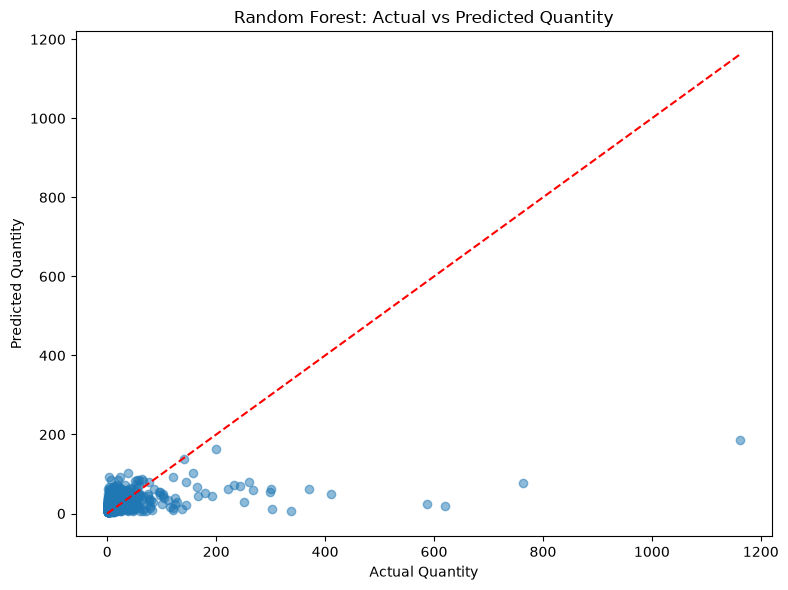

In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

charts_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Charts")
charts_dir.mkdir(parents=True, exist_ok=True)

# Plot a sample for readability
plot_data = comparison.sample(
    n=min(1000, len(comparison)),
    random_state=42
)

plt.figure(figsize=(8, 6))
plt.scatter(
    plot_data["Actual_Quantity"],
    plot_data["Predicted_Quantity"],
    alpha=0.5
)

max_value = max(
    plot_data["Actual_Quantity"].max(),
    plot_data["Predicted_Quantity"].max()
)

plt.plot([0, max_value], [0, max_value], "r--")
plt.xlabel("Actual Quantity")
plt.ylabel("Predicted Quantity")
plt.title("Random Forest: Actual vs Predicted Quantity")
plt.tight_layout()

plt.savefig(
    charts_dir / "Actual_vs_Predicted.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Parameter combinations to test
param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Time-based cross-validation
tscv = TimeSeriesSplit(n_splits=3)

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation MAE:")
print(round(-random_search.best_score_, 2))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 5}

Best cross-validation MAE:
18.59


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Best model selected by RandomizedSearchCV
best_model = random_search.best_estimator_

# Predict on the untouched test set
tuned_pred = best_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("TUNED MODEL RESULTS")
print("-" * 35)
print(f"MAE:  {tuned_mae:.2f}")
print(f"RMSE: {tuned_rmse:.2f}")
print(f"R²:   {tuned_r2:.4f}")

TUNED MODEL RESULTS
-----------------------------------
MAE:  20.20
RMSE: 61.99
R²:   0.0952


In [15]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Initial Random Forest",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2": tuned_r2
    }
])

display(model_comparison.round(4))

output_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Output")
output_dir.mkdir(parents=True, exist_ok=True)

model_comparison.to_csv(
    output_dir / "Model_Comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

,Model,MAE,RMSE,R2
0,Initial Random Forest,20.3925,62.1390,0.0910
1,Tuned Random Forest,20.1984,61.9946,0.0952


Model comparison saved successfully!


,Feature,Importance
0,Daily_Quantity,0.618364
1,Average_UnitPrice,0.295432
2,Transaction_Count,0.086204


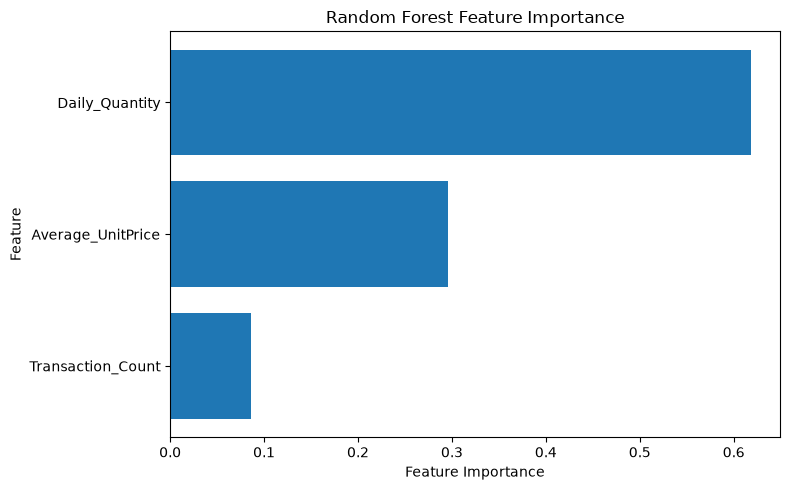

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Get feature importance from the tuned model
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df)

# Create chart
plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()

charts_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "Feature_Importance.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [17]:
# Prepare final test predictions
final_predictions = test_data[
    ["Date", "StockCode"]
].copy()

final_predictions["Actual_Quantity"] = y_test.to_numpy()
final_predictions["Predicted_Quantity"] = tuned_pred

final_predictions["Absolute_Error"] = (
    final_predictions["Actual_Quantity"]
    - final_predictions["Predicted_Quantity"]
).abs()

output_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Output")
output_dir.mkdir(parents=True, exist_ok=True)

final_predictions.to_csv(
    output_dir / "Final_Model_Predictions.csv",
    index=False
)

print("Final predictions saved successfully!")
display(final_predictions.head(10))

Final predictions saved successfully!


,Date,StockCode,Actual_Quantity,Predicted_Quantity,Absolute_Error
219041,2011-10-19,22839,2.0,5.636973,3.636973
219202,2011-10-19,23209,133.0,29.830103,103.169897
219411,2011-10-19,72122,4.0,19.455446,15.455446
218848,2011-10-19,22489,168.0,33.049352,134.950648
219570,2011-10-19,85180B,1.0,8.370451,7.370451
219482,2011-10-19,35471D,24.0,14.095878,9.904122
218500,2011-10-19,21181,30.0,19.812406,10.187594
219530,2011-10-19,84510A,2.0,20.444357,18.444357
219442,2011-10-19,84692,25.0,31.897193,6.897193
218855,2011-10-19,22504,2.0,5.423201,3.423201


In [18]:
metrics_df = pd.DataFrame([
    {"Metric": "MAE", "Value": tuned_mae},
    {"Metric": "RMSE", "Value": tuned_rmse},
    {"Metric": "R2", "Value": tuned_r2},
    {
        "Metric": "Best Cross-Validation MAE",
        "Value": -random_search.best_score_
    }
])

metrics_df.to_csv(
    output_dir / "Final_Model_Metrics.csv",
    index=False
)

print("Final metrics saved successfully!")
display(metrics_df.round(4))

Final metrics saved successfully!


,Metric,Value
0,MAE,20.1984
1,RMSE,61.9946
2,R2,0.0952
3,Best Cross-Validation MAE,18.5865


In [19]:
required_variables = [
    "df", "ml_data", "feature_cols",
    "best_model", "random_search",
    "tuned_mae", "tuned_rmse", "tuned_r2",
    "model_comparison", "importance_df"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    print("Please run the earlier cells first:", missing_variables)
else:
    print("All required results are available!")

All required results are available!


In [20]:
from pathlib import Path
import pandas as pd
from docx import Document
from docx.shared import Inches

output_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Output")
charts_dir = Path(r"D:\Yuva Intern Tasks\Task 5\Charts")
output_dir.mkdir(parents=True, exist_ok=True)

report = Document()

report.add_heading(
    "Week 5: Machine Learning Algorithms and Model Evaluation",
    0
)

report.add_paragraph(
    "YuvaIntern Data Analytics Internship"
)

report.add_heading("1. Project Objective", level=1)
report.add_paragraph(
    "The objective was to build and evaluate a machine learning model "
    "using the Online Retail dataset. A Random Forest Regressor was "
    "trained to predict the next recorded sales observation's quantity "
    "for a product."
)

report.add_heading("2. Tools and Technologies", level=1)
report.add_paragraph(
    "Python, Pandas, NumPy, scikit-learn, Matplotlib, Seaborn, "
    "and python-docx."
)

report.add_heading("3. Data Preprocessing", level=1)
report.add_paragraph(
    "Invoice dates and numeric columns were converted to appropriate "
    "types. Rows with missing essential fields, non-positive quantities, "
    "and non-positive unit prices were excluded. Daily product-level "
    "sales features were created, and the next recorded observation's "
    "quantity was used as the prediction target."
)

report.add_heading("4. Algorithm Selection", level=1)
report.add_paragraph(
    "Random Forest Regression was selected because it can model "
    "nonlinear relationships and interactions without requiring "
    "feature scaling. The model used daily quantity, average unit price, "
    "and transaction count as input features."
)

report.add_heading("5. Model Training and Hyperparameter Tuning", level=1)
report.add_paragraph(
    "The data was sorted chronologically and split into earlier "
    "training observations and later test observations. RandomizedSearchCV "
    "tested combinations of n_estimators, max_depth, min_samples_split, "
    "and min_samples_leaf using three time-based cross-validation splits. "
    "The selection metric was mean absolute error."
)

report.add_paragraph(
    f"Selected parameters: {random_search.best_params_}"
)
report.add_paragraph(
    f"Best cross-validation MAE: {-random_search.best_score_:.4f}"
)

report.add_heading("6. Model Evaluation", level=1)

metrics_table = report.add_table(rows=1, cols=2)
metrics_table.style = "Table Grid"
metrics_table.rows[0].cells[0].text = "Metric"
metrics_table.rows[0].cells[1].text = "Value"

for metric, value in [
    ("MAE", tuned_mae),
    ("RMSE", tuned_rmse),
    ("R-squared", tuned_r2)
]:
    cells = metrics_table.add_row().cells
    cells[0].text = metric
    cells[1].text = f"{value:.4f}"

report.add_paragraph(
    "MAE represents average absolute prediction error. RMSE penalizes "
    "larger errors more strongly. R-squared describes the variation "
    "explained by the model and can be negative on unseen data."
)

report.add_heading("7. Visualizations", level=1)

for filename, caption in [
    ("Actual_vs_Predicted.png", "Figure 1. Actual versus predicted quantity"),
    ("Feature_Importance.png", "Figure 2. Random Forest feature importance")
]:
    chart_path = charts_dir / filename
    if chart_path.exists():
        report.add_paragraph(caption)
        report.add_picture(str(chart_path), width=Inches(6))
    else:
        report.add_paragraph(
            f"{filename} was not found; generate the chart in the notebook."
        )

report.add_heading("8. Limitations", level=1)
report.add_paragraph(
    "The target represents the next recorded sales observation for a "
    "product, not necessarily the next calendar day. The dataset may "
    "omit days when a product had no recorded sales. The current features "
    "also do not include explicit product identity, calendar effects, "
    "or lagged sales history. Therefore, this model should not be treated "
    "as a production-ready demand forecasting system."
)

report.add_heading("9. Recommendations for Improvement", level=1)
report.add_paragraph(
    "Future work could build a complete product-date calendar, include "
    "zero-sales days, add lagged sales and calendar features, compare "
    "against a simple baseline, and validate the model on a later time "
    "period. Performance should be interpreted using the actual test "
    "metrics and the scale of the target."
)

report.add_heading("10. Conclusion", level=1)
report.add_paragraph(
    f"The tuned Random Forest achieved test MAE of {tuned_mae:.4f}, "
    f"RMSE of {tuned_rmse:.4f}, and R-squared of {tuned_r2:.4f}. "
    "These results provide an initial evaluation of the chosen approach; "
    "further validation and feature engineering are recommended."
)

report_path = output_dir / "YuvaIntern_Week5_Machine_Learning_Report.docx"
report.save(report_path)

print("Word report created successfully:")
print(report_path)

Word report created successfully:
D:\Yuva Intern Tasks\Task 5\Output\YuvaIntern_Week5_Machine_Learning_Report.docx


In [21]:
from pathlib import Path

report_path = Path(
    r"D:\Yuva Intern Tasks\Task 5\Output\YuvaIntern_Week5_Machine_Learning_Report.docx"
)

if report_path.exists():
    print("DOCX file successfully created!")
    print("File size:", round(report_path.stat().st_size / 1024, 2), "KB")
else:
    print("DOCX file not found. Please run the report-generation cell.")

DOCX file successfully created!
File size: 114.28 KB
